# FBPhophet
- [Prophet] (https://facebook.github.io/prophet/) es un software de código abierto lanzado por el equipo de Core Data Science de Facebook.
- Prophet es un procedimiento para pronosticar datos de series de tiempo basado en un modelo aditivo / multiplicativo donde las tendencias no lineales se ajustan a la estacionalidad anual, semanal y diaria, más los efectos de vacaciones.
- Funciona mejor con series de tiempo que tienen fuertes efectos estacionales y varias temporadas de datos históricos.
- Prophet es robusto ante los datos faltantes y los cambios en la tendencia, y generalmente maneja bien los valores atípicos.
- El paquete Prophet proporciona parámetros intuitivos que son fáciles de ajustar.

## Entorno

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Dataset

In [3]:
import os

ruta = os.getcwd()
ruta_csv = os.path.join(ruta, 'demanda.csv')
df = pd.read_csv(ruta_csv)
df.head()

,fecha,demanda,aforo_mensual,anomalia,mes,estacion
0,2010-01-01,35.00,7.000,0,1,primavera
1,2010-02-01,28.00,5.600,0,2,invierno
2,2010-03-01,30.80,7.280,0,3,invierno
3,2010-04-01,27.72,6.552,0,4,invierno
4,2010-05-01,41.58,9.828,0,5,otoño


## Preparación de Datos

In [4]:
df = df.rename(columns={'demanda': 'y', 'fecha':'ds'}) # <-- Prophet requiere que los nombres de las variables en la serie de tiempo sean: y = m3; ds = fecha
df['ds'] = pd.to_datetime(df['ds'])

## Separación
No aplica en FbProphet

## Algoritmo Univariable


### Entrenamiento

In [5]:
from prophet import Prophet

model = Prophet(yearly_seasonality=True, # <-- # Configuramos Prophet con estacionalidad anual (ideal para datos mensuales o estacionales)
                seasonality_mode='multiplicative', # <-- modo multiplicativo si la tendencia o estacionalidad crece proporcionalmente al nivel de la serie
                # changepoint_prior_scale=0.5,  # Valor más alto = mayor flexibilidad ante cambios de tendencia
                # growth = 'logistic'
                )

# model.add_country_holidays(country_name='PE') # <-- Si deseas agregar feriados del pais

model.fit(df)

Importing plotly failed. Interactive plots will not work.
c:\Users\games\OneDrive\DS\Clases\Portafolio\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
21:34:26 - cmdstanpy - INFO - Chain [1] start processing
21:34:27 - cmdstanpy - INFO - Chain [1] done processing


#### Predicciones

In [6]:
# Creamos el dataframe futuro. Como tus datos parecen mensuales ('MS' = Inicio de mes), 
periods_to_predict = 12  # Validamos el test y proyectamos 12 meses más hacia el futuro o según el periodo que necesites predecir
future = model.make_future_dataframe(periods=periods_to_predict, freq='MS')
future.tail(12)

,ds
202,2026-11-01
203,2026-12-01
204,2027-01-01
205,2027-02-01
206,2027-03-01
207,2027-04-01
208,2027-05-01
209,2027-06-01
210,2027-07-01
211,2027-08-01


In [7]:
# Agregar la columna 'cap' con el mismo límite máximo
# future['cap'] = 89 # <-- Usar solo si se va a poner un límite superior que no se puede alcanzar: # Ajusta este valor según el límite máximo de tu serie

forecast = model.predict(future)
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(12)

,ds,yhat,yhat_lower,yhat_upper
202,2026-11-01,94.976515,90.431240,99.283511
203,2026-12-01,190.822933,186.120368,195.608764
204,2027-01-01,59.462055,54.770715,64.045983
205,2027-02-01,47.492480,42.697982,52.228648
206,2027-03-01,53.371318,48.393828,57.968969
207,2027-04-01,47.928749,43.043838,52.634129
208,2027-05-01,71.457972,66.804337,76.328011
209,2027-06-01,84.779673,80.167505,89.534801
210,2027-07-01,67.439973,62.527441,71.948972
211,2027-08-01,59.920326,55.053548,64.577382


#### Evaluación

##### Evaluación de Predicción (Opcional)

El R^2 no es confiable en series de tiempo por tres razones:
- Efecto tendencia: Un valor alto suele reflejar solo la tendencia o estacionalidad general, enmascarando errores en cambios o fluctuaciones finas.
- Autocorrelación: Viola el supuesto estadístico de que los errores son independientes entre sí.
- Enfoque retrospectivo: Mide el ajuste histórico de los datos y no la capacidad real de pronóstico a futuro.

In [8]:
from sklearn.metrics import (mean_squared_error, r2_score, mean_absolute_error, median_absolute_error)

def evaluate_forecast(y_true, y_pred):
    results = pd.DataFrame({
        'r2_score': [r2_score(y_true, y_pred)],
        'mean_absolute_error': [mean_absolute_error(y_true, y_pred)],
        'median_absolute_error': [median_absolute_error(y_true, y_pred)],
        'mse': [mean_squared_error(y_true, y_pred)],
        'rmse': [np.sqrt(mean_squared_error(y_true, y_pred))]
    })
    return results


In [9]:
# Extraemos las predicciones correspondientes únicamente al periodo de validación
# Alineamos por fecha para comparar exactamente los valores reales vs predichos
eval_forecast = df.merge(forecast[['ds', 'yhat']], on='ds', how='inner')
predictions_valid = eval_forecast['yhat'].values
actuals_valid = eval_forecast['y'].values

In [10]:
# Calcular métricas de error en validación
metrics_results = evaluate_forecast(actuals_valid, predictions_valid)
print("\n--- Métricas de Evaluación en Validación ---")
metrics_results


--- Métricas de Evaluación en Validación ---


,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.985358,1.636705,0.536064,13.066533,3.614766


In [11]:
evaluate_forecast(actuals_valid[-12:], predictions_valid[-12:]) # Mide el error en los últimos 12 meses (ajuste in-sample)

,r2_score,mean_absolute_error,median_absolute_error,mse,rmse
0,0.999108,0.85165,0.78397,1.199777,1.095343


##### Evaluación de Predicción
Validación Cruzada: Prophet está diseñado principalmente para diagnosticar el rendimiento mediante Validación Cruzada histórica deslizante (rolling cross-validation con cross_validation), en lugar de una partición estática simple de entrenamiento y prueba.Si utilizas el flujo oficial de Prophet con validación cruzada (cross_validation) y performance_metrics, no necesitas separar manualmente un df_train y df_test tradicional de una sola partición

In [12]:
from prophet.diagnostics import cross_validation

# Equivalencias aproximadas en días:
# 1 mes = 30 días (aprox)
# 2 años = 730 días
# 6 meses = 180 días
# 12 meses = 365 días

df_cv = cross_validation(
    model,                  # Usando tu variable 'model'
    initial='730 days',     # Ej: 2 años de entrenamiento inicial
    period='180 days',      # Ej: Realizar un corte cada 6 meses ('6M')
    horizon='365 days'      # Ej: Pronosticar los siguientes 12 meses ('12M')
)

  0%|          | 0/28 [00:00<?, ?it/s]21:34:32 - cmdstanpy - INFO - Chain [1] start processing
21:34:57 - cmdstanpy - INFO - Chain [1] done processing
  4%|▎         | 1/28 [00:25<11:21, 25.23s/it]21:34:57 - cmdstanpy - INFO - Chain [1] start processing
21:35:33 - cmdstanpy - INFO - Chain [1] done processing
  7%|▋         | 2/28 [01:01<13:48, 31.87s/it]21:35:33 - cmdstanpy - INFO - Chain [1] start processing
21:36:13 - cmdstanpy - INFO - Chain [1] done processing
 11%|█         | 3/28 [01:41<14:44, 35.37s/it]21:36:13 - cmdstanpy - INFO - Chain [1] start processing
21:36:14 - cmdstanpy - INFO - Chain [1] done processing
 14%|█▍        | 4/28 [01:42<08:41, 21.74s/it]21:36:14 - cmdstanpy - INFO - Chain [1] start processing
21:36:14 - cmdstanpy - INFO - Chain [1] done processing
 18%|█▊        | 5/28 [01:42<05:24, 14.09s/it]21:36:14 - cmdstanpy - INFO - Chain [1] start processing
21:36:15 - cmdstanpy - INFO - Chain [1] done processing
 21%|██▏       | 6/28 [01:43<03:29,  9.50s/it]21:36:15

In [13]:
df_cv.head()

,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2012-07-01,40.769965,40.757186,40.782878,40.561109,2012-06-11
1,2012-08-01,36.950347,36.912750,36.987622,36.504998,2012-06-11
2,2012-09-01,40.796330,40.712113,40.879081,40.155498,2012-06-11
3,2012-10-01,48.890621,48.728018,49.053144,48.186597,2012-06-11
4,2012-11-01,58.565772,58.308651,58.844841,57.823917,2012-06-11


In [14]:
from prophet.diagnostics import register_performance_metric, rolling_mean_by_h, performance_metrics

df_hist_y = df['y'].values

@register_performance_metric
def mase(df, w):
    """Mean absolute scale error"""
    e = (df['y'] - df['yhat'])
    d = np.abs(np.diff(df_hist_y)).mean()  # df_hist_y = serie histórica completa
    se = np.abs(e / d)
    if w < 0:
        return pd.DataFrame({'horizon': df['horizon'], 'mase': se})
    return rolling_mean_by_h(
        x=se.values, h=df['horizon'].values, w=w, name='mase'
    )

df_mase = performance_metrics(df_cv, metrics=['mase'])
df_mase.head()

,horizon,mase
0,37 days,0.245638
1,39 days,0.232243
2,40 days,0.308605
3,41 days,0.304613
4,42 days,0.302991


In [15]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,90.939901,9.536241,4.966399,0.071787,0.003833,0.075651,0.181818
1,39 days,88.459077,9.405269,4.695570,0.064262,0.003033,0.068976,0.181818
2,40 days,167.442763,12.939968,6.239478,0.072725,0.003833,0.078821,0.181818
3,41 days,166.978451,12.922014,6.158779,0.071102,0.003833,0.077289,0.181818
4,42 days,166.602378,12.907454,6.125973,0.070028,0.003833,0.076313,0.212121


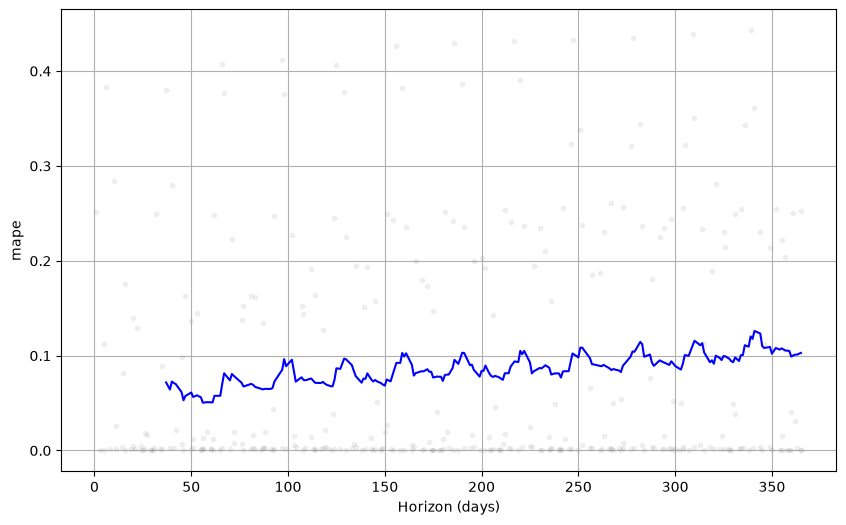

In [16]:
from prophet.plot import plot_cross_validation_metric
fig = plot_cross_validation_metric(df_cv, metric='mape')

##### Gráfica para la Validación

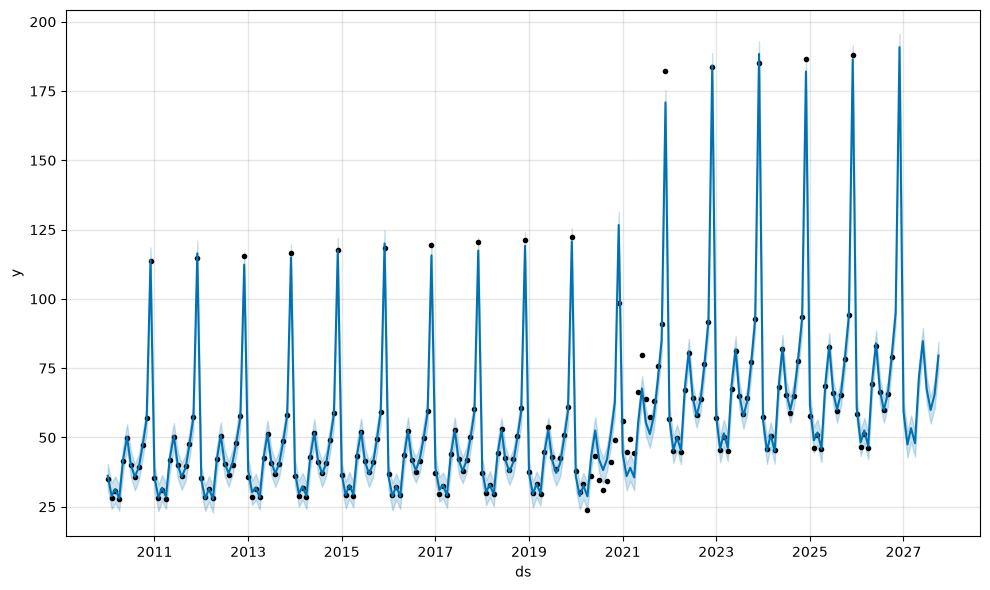

In [17]:
fig1 = model.plot(forecast)
# plt.axhline(y=0, color='red') # <-- Dibuja la linea roja si quieres poner un límite

##### Puntos de Cambio de Tendencia

Prophet coloca de forma automática potenciales puntos de cambio distribuidos en el primer 80% de las fechas históricas de tu serie temporal.

Selección por regularización: El algoritmo evalúa en cuáles de esos puntos ocurre un cambio de pendiente estadísticamente relevante según la penalización estándar (changepoint_prior_scale=0.05 por defecto) y marca los más importantes.

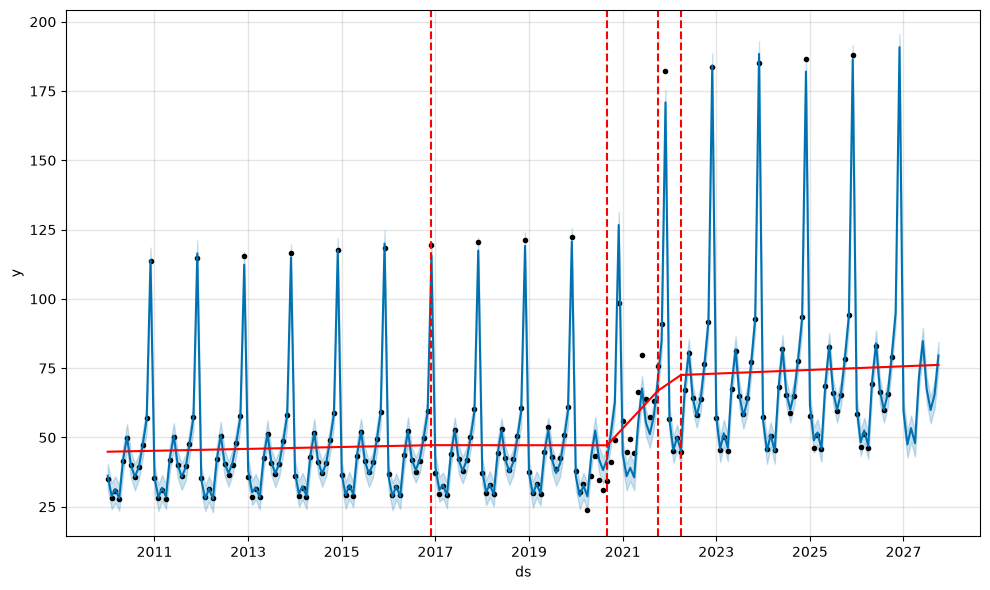

In [18]:
from prophet.plot import add_changepoints_to_plot
fig = model.plot(forecast)
a = add_changepoints_to_plot(fig.gca(), model, forecast)

##### Gráfico de Punto de Cambio
En este ejemplo, no figura el punto de cambio

21:36:26 - cmdstanpy - INFO - Chain [1] start processing
21:36:26 - cmdstanpy - INFO - Chain [1] done processing


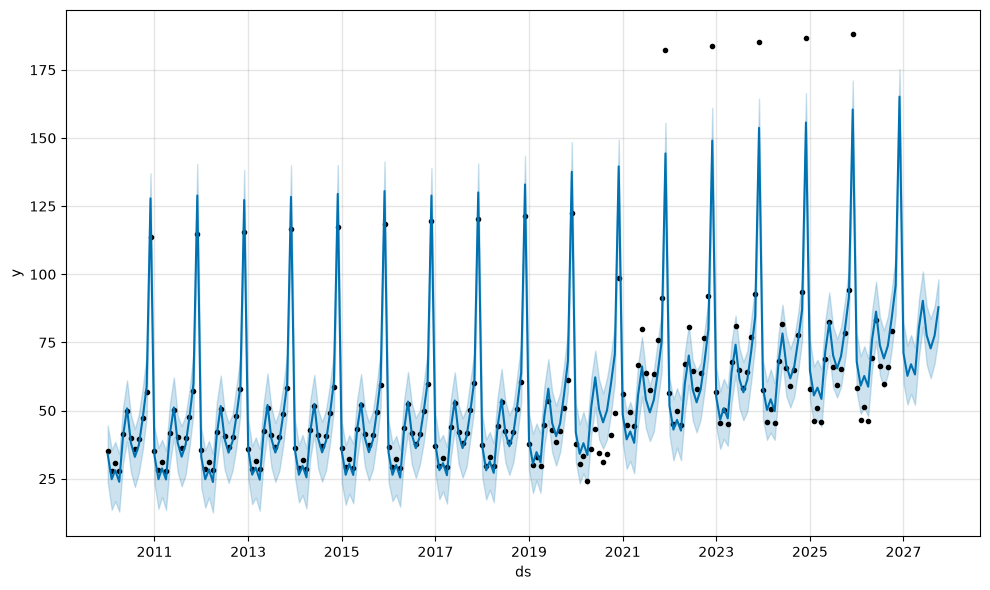

In [19]:
model_cp = Prophet(changepoints=[df['ds'].iloc[len(df)//2].strftime('%Y-%m-%d')])  # o una fecha real de tu serie
forecast_cp = model_cp.fit(df).predict(future)
fig = model_cp.plot(forecast_cp)

##### Gráfica de Descomposición de Componentes

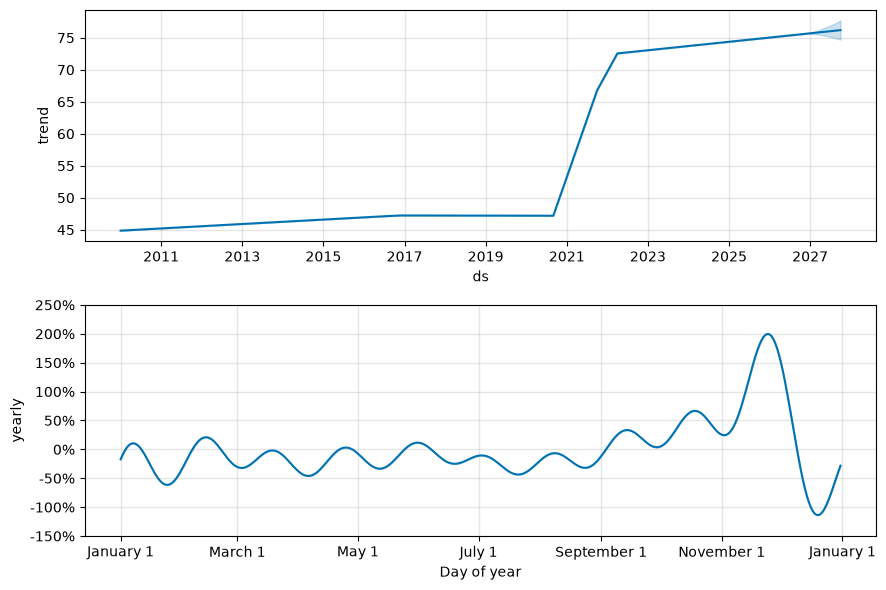

In [20]:
# Gráfica de componentes (Tendencia y Estacionalidad)
fig_components = model.plot_components(forecast)
plt.show()

En Prophet, si el eje $y$ de la estacionalidad multiplicativa muestra números enteros grandes (como 75 en lugar de 0.75), la librería los interpreta directamente como factores multiplicativos (es decir, +75 equivale a multiplicar la tendencia por 76), lo cual suele generar proyecciones explosivas o irreales si tu demanda base es pequeña

##### Hiperparámetros

In [21]:
# Generar cutoffs dinámicos (cada 180 días, dejando 365 días de horizonte)
initial_date = df['ds'].min() + pd.Timedelta(days=730)
end_date = df['ds'].max() - pd.Timedelta(days=365)
cutoffs = pd.date_range(start=initial_date, end=end_date, freq='180D')

In [ ]:
import itertools

# Definir la cuadrícula de parámetros a evaluar
param_grid = {  
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'seasonality_prior_scale': [0.1, 1.0, 10.0],
}

# Generar todas las combinaciones posibles de parámetros
all_params = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]
rmses = []  # Almacenar los RMSEs para cada combinación

# Bucle para probar cada combinación mediante validación cruzada
for params in all_params:
    m = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', **params).fit(df)
    df_cv_i = cross_validation(
        m,
        cutoffs=cutoffs,
        horizon='365 days',
        parallel="processes"
    )
    df_p = performance_metrics(df_cv_i, rolling_window=1)
    rmses.append(df_p['rmse'].values[0])

# Estructurar los resultados y encontrar los mejores hiperparámetros
tuning_results = pd.DataFrame(all_params)
tuning_results['rmse'] = rmses
print("--- Resultados de la Optimización ---")
print(tuning_results)

# Limpiar posibles nulos, extraer el mejor set y entrenar el modelo final
tuning_results = tuning_results.dropna(subset=['rmse'])
best_params = tuning_results.loc[tuning_results['rmse'].idxmin()].drop('rmse').to_dict()

print("\nMejores parámetros encontrados:", best_params)

# Entrenar el modelo definitivo con la mejor configuración
model_final = Prophet(yearly_seasonality=True, seasonality_mode='multiplicative', **best_params).fit(df)

21:36:27 - cmdstanpy - INFO - Chain [1] start processing
21:36:28 - cmdstanpy - INFO - Chain [1] done processing
21:37:26 - cmdstanpy - INFO - Chain [1] start processing
21:37:26 - cmdstanpy - INFO - Chain [1] done processing
21:38:22 - cmdstanpy - INFO - Chain [1] start processing
21:38:23 - cmdstanpy - INFO - Chain [1] done processing
21:39:26 - cmdstanpy - INFO - Chain [1] start processing
21:39:27 - cmdstanpy - INFO - Chain [1] done processing
21:40:23 - cmdstanpy - INFO - Chain [1] start processing
21:40:23 - cmdstanpy - INFO - Chain [1] done processing
21:41:22 - cmdstanpy - INFO - Chain [1] start processing
21:41:22 - cmdstanpy - INFO - Chain [1] done processing
21:42:18 - cmdstanpy - INFO - Chain [1] start processing
21:42:18 - cmdstanpy - INFO - Chain [1] done processing
21:43:13 - cmdstanpy - INFO - Chain [1] start processing
21:43:13 - cmdstanpy - INFO - Chain [1] done processing
21:44:10 - cmdstanpy - INFO - Chain [1] start processing
21:44:11 - cmdstanpy - INFO - Chain [1]

--- Resultados de la Optimización ---
   changepoint_prior_scale  seasonality_prior_scale       rmse
0                     0.01                      0.1   9.887029
1                     0.01                      1.0  10.009107
2                     0.01                     10.0   9.961433
3                     0.05                      0.1  10.437916
4                     0.05                      1.0  10.362042
5                     0.05                     10.0  10.392712
6                     0.10                      0.1  10.348847
7                     0.10                      1.0  10.374855
8                     0.10                     10.0  10.378245

Mejores parámetros encontrados: {'changepoint_prior_scale': 0.01, 'seasonality_prior_scale': 0.1}
